# 01 - Exploratory data analysis (EDA)
**Goal:** understand the data *before* modelling. EDA answers: what do the numbers look like, are there
oddities, and which relationships might a model be able to use?

Run `python download_data.py` first. Only the **training** split is used here, so the test set stays
untouched and cannot influence any modelling decision.

In [1]:
import sys; sys.path.insert(0, '..')
import matplotlib.pyplot as plt
import pandas as pd
from src import config as C
from src.data import load_split

X_train, X_test, y_train, y_test = load_split()
df = X_train.assign(strength=y_train)      # 8 input features + the target = 9 columns
print(df.shape)

(804, 9)


## 1. Summary statistics
`describe()` gives, for every column: **count** (rows), **mean**, **std** (typical spread around the mean),
**min / max** (extremes), and the **25% / 50% / 75%** quartiles (the median is 50%).

What to look for:
* *Different scales:* cement is in the hundreds, superplasticizer in the tens. That is why the pipeline standardises features.
* *Min = 0 with a low 25% or 50%:* many mixes simply do not contain slag, fly ash or superplasticizer.
* *Mean far from median:* a skewed column.
* *Max far above the 75% quartile:* possible outliers.

In [2]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cement,804.0,278.18,103.94,102.00,190.34,265.50,349.00,540.00
slag,804.0,72.07,86.09,0.00,0.00,20.00,140.32,359.40
fly_ash,804.0,56.32,64.35,0.00,0.00,0.00,118.31,200.10
water,804.0,182.11,21.54,121.75,166.61,185.70,192.18,246.90
superplasticizer,804.0,6.08,5.95,0.00,0.00,6.12,10.00,32.20
coarse_aggregate,804.0,972.60,77.29,801.00,932.00,968.00,1028.40,1134.30
fine_aggregate,804.0,773.42,80.92,594.00,728.68,780.20,825.00,992.60
age,804.0,45.31,62.35,1.00,14.00,28.00,56.00,365.00
strength,804.0,35.07,16.02,3.32,23.22,33.74,44.39,79.99


## 2. Histograms of all 9 columns
A histogram shows *how often* each value range occurs (x = value, y = number of rows). Drawing all columns
at once lets you compare their shapes quickly.

What to look for:
* a **tall bar at 0** (slag, fly ash, superplasticizer): "ingredient not used", not a measurement error;
* **gaps / spikes** in `age`: samples were only tested at fixed ages (7, 28, 90 days, ...), so age is a handful of discrete values;
* skewed shapes and the shape of `strength`, the target.

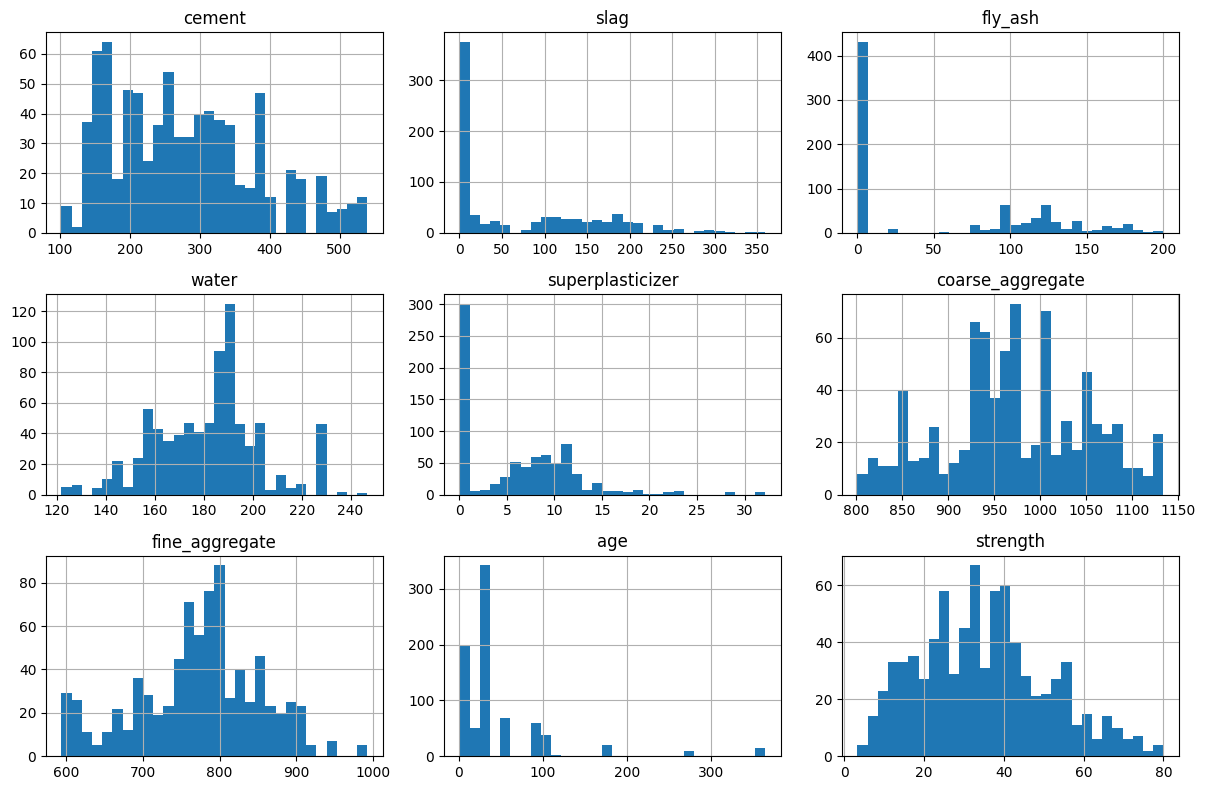

In [3]:
df.hist(bins=30, figsize=(12, 8)); plt.tight_layout()

## 3. Mean strength vs. age
For each tested age we average the strength of all samples of that age. This isolates the single most important
non-linear relationship in the data.

What to look for: strength climbs steeply in the first days/weeks and then **flattens**. A straight line
(degree 1) cannot follow that bend, which is exactly why polynomial terms (and maybe `log(age)`, see notebook 02) help.

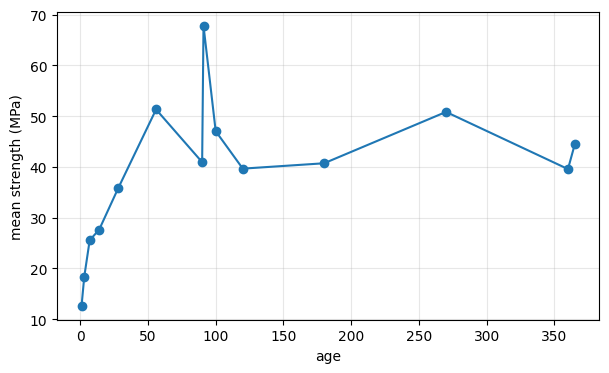

In [4]:
df.groupby('age')['strength'].mean().plot(marker='o', figsize=(7, 4), ylabel='mean strength (MPa)')
plt.grid(alpha=.3)

## 4. Correlation heat map
Each cell is the **Pearson correlation** between two columns: a number from -1 to +1.
* **+1**: when one rises the other rises in lockstep. **-1**: one rises as the other falls. **0**: no *linear* relationship.
* Read the **strength** row/column to see which inputs relate linearly to the target (positive and negative).
* Read the **input-vs-input** cells for *multicollinearity* (inputs that move together, e.g. recipes that trade water for superplasticizer).
  Strongly correlated inputs make OLS coefficients unstable, which is one reason Ridge helps.

Caveat: correlation only measures *linear* association. A weak correlation (like age) can hide a strong curved relationship.

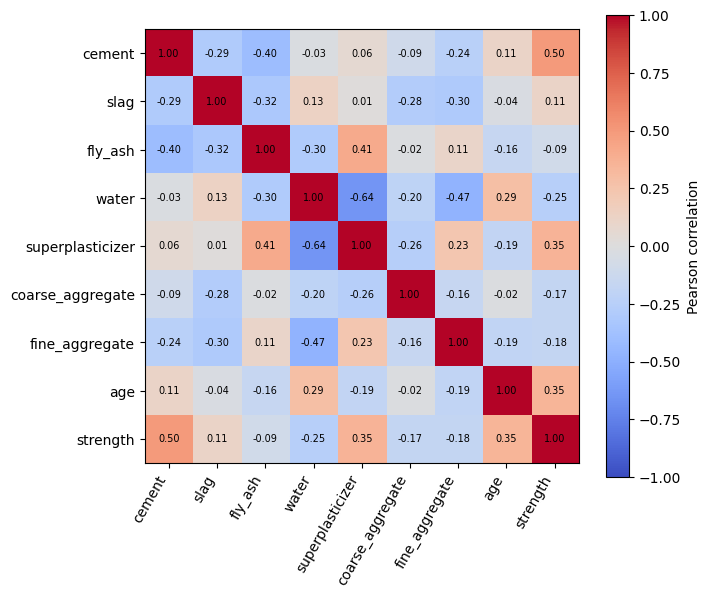

In [5]:
corr = df.corr()
plt.figure(figsize=(7, 6)); plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=60, ha='right'); plt.yticks(range(len(corr)), corr.columns)
plt.colorbar(label='Pearson correlation')
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)